# Student Enrollment Funnel, Cohort & A/B Test Analysis
**Question:** Where do prospective students drop out of the admissions funnel, which channels bring students who actually enrol, and did a WhatsApp reminder improve counselling-call connection?

Data: 9,240 real leads from X Education (online courses). Dates, the application stage and the A/B test are **simulated** (seeded) because the public data has none - see README.
Run `python src/build_tables.py` and `python src/run_sql.py` first.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

P = '../data/processed/'
leads = pd.read_csv(P + 'leads_clean.csv', parse_dates=['lead_created_date', 'enrolled_date'])
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'font.size': 10})
BLUE, GREY, ORANGE = '#2a6fdb', '#b8c2cc', '#e8833a'
leads.shape

(9240, 21)

## 1. Data quality checks
Double-check before analysing: duplicates, nulls, funnel logic (each stage must be a subset of the previous one).

In [2]:
checks = {
    'rows': len(leads),
    'duplicate lead_ids': leads.lead_id.duplicated().sum(),
    'null lead_source': leads.lead_source.isna().sum(),
    'enrolled but no enrolled_date': ((leads.stage_5_enrolled == 1) & leads.enrolled_date.isna()).sum(),
    'enrolled_date before lead date': (leads.enrolled_date < leads.lead_created_date).sum(),
}
stages = ['stage_1_lead', 'stage_2_engaged', 'stage_3_counselled', 'stage_4_applied', 'stage_5_enrolled']
for a, b in zip(stages, stages[1:]):
    checks[f'{b} without {a}'] = ((leads[b] == 1) & (leads[a] == 0)).sum()
pd.Series(checks, name='value').to_frame()

,value
rows,9240
duplicate lead_ids,0
null lead_source,0
enrolled but no enrolled_date,0
enrolled_date before lead date,0
stage_2_engaged without stage_1_lead,0
stage_3_counselled without stage_2_engaged,0
stage_4_applied without stage_3_counselled,0
stage_5_enrolled without stage_4_applied,0


## 2. Funnel - where do students drop off?

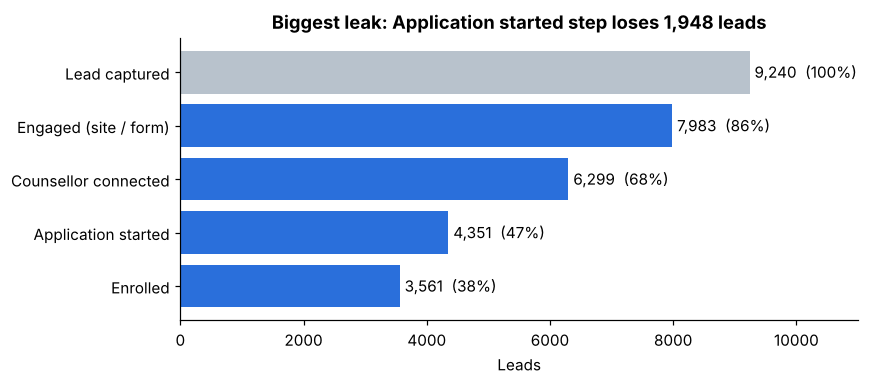

,stage_no,stage,leads,pct_of_leads,step_conversion_pct,dropped_at_step
0,1,Lead captured,9240,100.0,NaN,NaN
1,2,Engaged (site / form),7983,86.4,86.4,1257.0
2,3,Counsellor connected,6299,68.2,78.9,1684.0
3,4,Application started,4351,47.1,69.1,1948.0
4,5,Enrolled,3561,38.5,81.8,790.0


In [3]:
funnel = pd.read_csv(P + 'funnel.csv')
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(funnel.stage[::-1], funnel.leads[::-1], color=[BLUE]*4 + [GREY])
for i, (n, pct) in enumerate(zip(funnel.leads[::-1], funnel.pct_of_leads[::-1])):
    ax.text(n + 80, i, f'{n:,}  ({pct:.0f}%)', va='center')
worst = funnel.loc[funnel.dropped_at_step.idxmax()]
ax.set_title(f"Biggest leak: {worst.stage} step loses {int(worst.dropped_at_step):,} leads")
ax.set_xlim(0, 11000); ax.set_xlabel('Leads')
plt.tight_layout(); plt.savefig('../images/funnel.png'); plt.show()
funnel

## 3. Channels - volume is not the same as quality

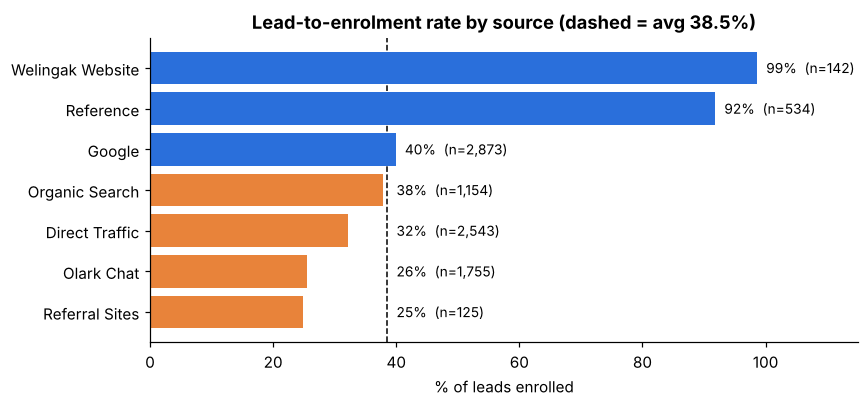

,lead_source,leads,share_of_leads_pct,counselled_pct,applied_pct,enrolled,lead_to_enrol_pct,share_of_enrolments_pct,avg_time_on_site_min
0,Google,2873,31.1,80.9,51.7,1147,39.9,32.2,10.9
1,Direct Traffic,2543,27.5,70.7,43.5,818,32.2,23.0,10.1
2,Olark Chat,1755,19.0,29.6,26.6,448,25.5,12.6,1.0
3,Organic Search,1154,12.5,71.8,48.5,436,37.8,12.2,10.5
4,Reference,534,5.8,95.9,92.3,490,91.8,13.8,4.2
5,Welingak Website,142,1.5,100.0,99.3,140,98.6,3.9,2.4
6,Referral Sites,125,1.4,85.6,37.6,31,24.8,0.9,9.0


In [4]:
src = pd.read_csv(P + 'source_performance.csv').query('leads >= 100').sort_values('lead_to_enrol_pct')
avg = leads.stage_5_enrolled.mean() * 100
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(src.lead_source, src.lead_to_enrol_pct, color=[ORANGE if v < avg else BLUE for v in src.lead_to_enrol_pct])
ax.axvline(avg, color='black', ls='--', lw=1, zorder=0)
for i, (v, n) in enumerate(zip(src.lead_to_enrol_pct, src.leads)):
    ax.text(max(v, avg) + 1.5, i, f'{v:.0f}%  (n={n:,})', va='center', fontsize=9)
ax.set_title(f'Lead-to-enrolment rate by source (dashed = avg {avg:.1f}%)'); ax.set_xlabel('% of leads enrolled'); ax.set_xlim(0, 115)
plt.tight_layout(); plt.savefig('../images/sources.png'); plt.show()
src.sort_values('leads', ascending=False)

## 4. Engagement - does time on site predict enrolment? (real data)

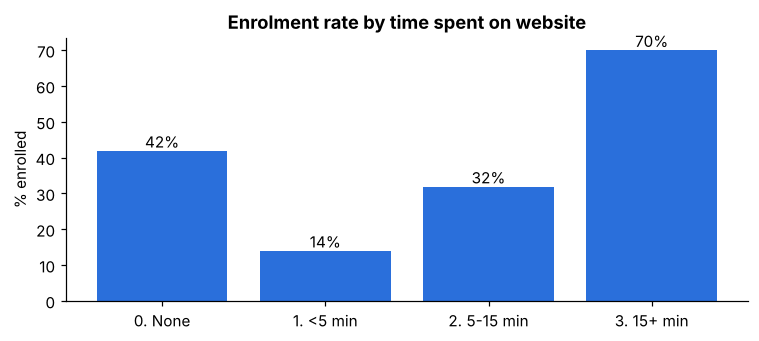

                         size   mean
lead_origin                         
API                      1603  0.242
Landing Page Submission     3  0.000
Lead Add Form             557  0.932
Lead Import                30  0.300


,engagement_band,leads,enrolled,lead_to_enrol_pct
0,0. None,2193,916,41.8
1,1. <5 min,2844,396,13.9
2,2. 5-15 min,1807,575,31.8
3,3. 15+ min,2396,1674,69.9


In [5]:
eng = pd.read_csv(P + 'engagement.csv')
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(eng.engagement_band, eng.lead_to_enrol_pct, color=BLUE)
for i, v in enumerate(eng.lead_to_enrol_pct): ax.text(i, v + 1, f'{v:.0f}%', ha='center')
ax.set_title('Enrolment rate by time spent on website'); ax.set_ylabel('% enrolled')
plt.tight_layout(); plt.savefig('../images/engagement.png'); plt.show()
# '0. None' is high because offline/referral leads (Lead Add Form, Reference) convert without visiting the site
print(leads[leads.engagement_band == '0. None'].groupby('lead_origin').stage_5_enrolled.agg(['size', 'mean']).round(3))
eng

## 5. Cohorts - how fast does each monthly cohort enrol? (Pandas)

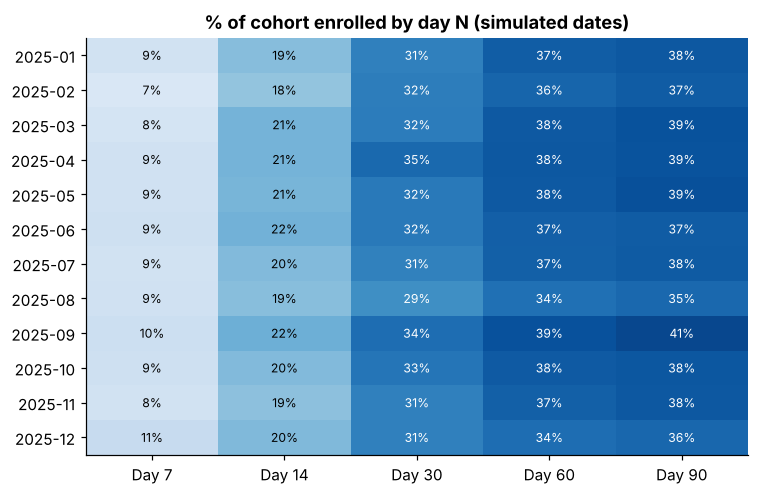

,leads,D7,D14,D30,D60,D90
cohort_month,,,,,,
2025-01,562,8.7,19.4,31.0,37.2,38.1
2025-02,531,6.8,18.1,31.6,35.8,37.3
2025-03,682,7.9,21.3,31.8,37.8,39.1
2025-04,742,8.9,21.4,35.0,38.0,38.9
2025-05,933,8.8,21.0,32.2,37.9,39.4
2025-06,1035,9.4,21.7,32.3,36.8,37.3
2025-07,1004,8.6,19.9,30.8,36.6,37.5
2025-08,844,8.9,19.2,28.6,33.9,35.2
2025-09,732,9.8,22.3,34.3,39.2,40.8


In [6]:
days = [7, 14, 30, 60, 90]
coh = (leads.assign(**{f'D{d}': (leads.days_to_enroll <= d) for d in days})
            .groupby('cohort_month')[[f'D{d}' for d in days]].mean().mul(100).round(1))
coh.insert(0, 'leads', leads.groupby('cohort_month').size())
fig, ax = plt.subplots(figsize=(7, 4.6))
im = ax.imshow(coh[[f'D{d}' for d in days]], cmap='Blues', aspect='auto', vmin=0, vmax=45)
ax.set_xticks(range(len(days)), [f'Day {d}' for d in days]); ax.set_yticks(range(len(coh)), coh.index)
for i in range(len(coh)):
    for j, d in enumerate(days):
        v = coh.iloc[i][f'D{d}']; ax.text(j, i, f'{v:.0f}%', ha='center', va='center', fontsize=8,
                                          color='white' if v > 28 else 'black')
ax.set_title('% of cohort enrolled by day N (simulated dates)')
plt.tight_layout(); plt.savefig('../images/cohorts.png'); plt.show()
coh

In [7]:
# Channel cohorts: day-30 enrolment rate by source
d30 = (leads.assign(d30=leads.days_to_enroll <= 30).groupby('lead_source')
            .agg(leads=('lead_id', 'size'), enrolled_by_d30=('d30', 'mean')).query('leads >= 100'))
d30['enrolled_by_d30'] = (d30.enrolled_by_d30 * 100).round(1)
d30['vs_google_x'] = (d30.enrolled_by_d30 / d30.loc['Google', 'enrolled_by_d30']).round(2)
d30.sort_values('enrolled_by_d30', ascending=False)

,leads,enrolled_by_d30,vs_google_x
lead_source,,,
Welingak Website,142,78.9,2.29
Reference,534,68.5,1.99
Google,2873,34.5,1.00
Organic Search,1154,32.7,0.95
Direct Traffic,2543,27.6,0.80
Referral Sites,125,20.0,0.58
Olark Chat,1755,19.0,0.55


## 6. A/B test - WhatsApp reminder before the counselling call (simulated)
**Hypothesis:** a WhatsApp reminder 2 hours before the call raises the share of leads connected within 48h.
**Primary metric:** call connected within 48h. **Design:** 50/50 random split of Sep-Dec 2025 leads, two-sided test, α = 0.05.

In [8]:
ab = leads.dropna(subset=['ab_group'])
g = ab.groupby('ab_group').call_connected_48h.agg(['size', 'sum', 'mean'])
print(g, '\n')

# 1) Sample-ratio mismatch check (was the 50/50 split healthy?)
srm_p = stats.chisquare(g['size']).pvalue
print(f'SRM check p = {srm_p:.3f}  ->', 'OK' if srm_p > 0.01 else 'PROBLEM')

# 2) Two-proportion z-test
z, p = proportions_ztest(g.loc[['treatment', 'control'], 'sum'], g.loc[['treatment', 'control'], 'size'])
lo, hi = confint_proportions_2indep(g.loc['treatment', 'sum'], g.loc['treatment', 'size'],
                                    g.loc['control', 'sum'], g.loc['control', 'size'])
diff = g.loc['treatment', 'mean'] - g.loc['control', 'mean']
print(f'Lift = {diff*100:+.2f} pp   95% CI [{lo*100:+.2f}, {hi*100:+.2f}] pp   z = {z:.2f}   p = {p:.3f}')

# 3) Power: how many leads per arm were needed to detect a +3 pp lift?
base = g.loc['control', 'mean']
es = proportion_effectsize(base + 0.03, base)
n_needed = NormalIndPower().solve_power(effect_size=es, alpha=0.05, power=0.8)
achieved = NormalIndPower().power(effect_size=es, nobs1=g['size'].min(), alpha=0.05)
print(f'Needed per arm for +3pp at 80% power: {n_needed:,.0f}  |  we had {g["size"].min():,} '
      f'-> power was only {achieved:.0%}')

           size    sum      mean
ab_group                        
control    1482  814.0  0.549258
treatment  1425  762.0  0.534737 

SRM check p = 0.290  -> OK
Lift = -1.45 pp   95% CI [-5.07, +2.17] pp   z = -0.79   p = 0.432
Needed per arm for +3pp at 80% power: 4,287  |  we had 1,425 -> power was only 37%


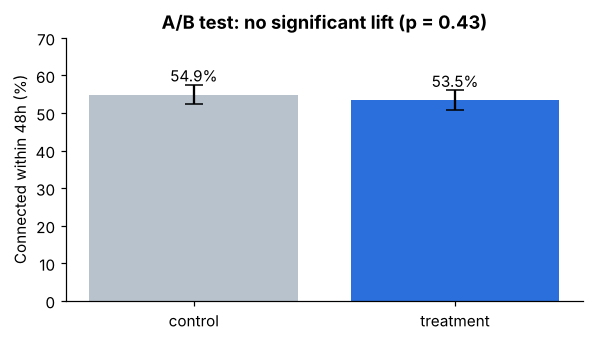

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 3.2))
rates = g['mean'] * 100
ax.bar(rates.index, rates, color=[GREY, BLUE])
se = np.sqrt(g['mean'] * (1 - g['mean']) / g['size']) * 196
ax.errorbar(rates.index, rates, yerr=se, fmt='none', color='black', capsize=6)
for i, v in enumerate(rates): ax.text(i, v + 3.5, f'{v:.1f}%', ha='center')
ax.set_ylim(0, 70); ax.set_ylabel('Connected within 48h (%)')
ax.set_title(f'A/B test: no significant lift (p = {p:.2f})')
plt.tight_layout(); plt.savefig('../images/ab_test.png'); plt.show()

## 7. So what? Recommendations
1. **Fix the counsellor-connection and application steps first** - they lose the most leads (see funnel). Unreachable numbers (`Ringing`, `switched off`, `invalid number`) are the main reason: validate phone numbers on the form (OTP) and add a second contact channel.
2. **Shift budget and effort towards Reference / Welingak and away from Olark Chat** - Reference leads enrol at ~92% vs ~26% for Olark Chat, yet Olark Chat brings 3.5x more leads. Treat chat leads as nurture, not hot leads.
3. **Prioritise counsellor calls by engagement** - leads spending 15+ min on the site enrol at ~70% vs ~14% for <5 min. A simple time-on-site rule is a cheap first lead score.
4. **Don't roll out the WhatsApp reminder yet** - the result is not significant and the test was under-powered. It had ~37% power to detect a +3 pp lift; it needs ~4,300 leads per arm (~3x the sample) before deciding.